In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Manufacturing_Production_Data.csv to Manufacturing_Production_Data.csv


In [3]:
df = pd.read_csv("Manufacturing_Production_Data.csv")

In [4]:
df.head()

,Date,Day,Month,QTR,Shift,Machine ID,Product,Operator,Units Produced,Units Defective,...,Ideal Cycle Time,Total Cost,Total Revenue,Profit,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28
0,2026-01-01,Thursday,January,QTR-1,Morning,M-101,Steel Bracket,A. Ramesh,407,5,...,1.179361,18315,27676,9361,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-01-01,Thursday,January,QTR-1,Morning,M-102,Steel Bracket,M. Nair,401,29,...,1.104738,18045,27268,9223,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-01-01,Thursday,January,QTR-1,Morning,M-103,Motor Shaft,R. Singh,464,18,...,1.034483,69600,97440,27840,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-01-01,Thursday,January,QTR-1,Morning,M-104,Gear Housing,M. Nair,538,7,...,0.823420,64560,94150,29590,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-01-01,Thursday,January,QTR-1,Morning,M-105,Steel Bracket,K. Reddy,540,21,...,0.888889,24300,36720,12420,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print(df.columns.tolist())

['Date', 'Day', 'Month', 'QTR', 'Shift', 'Machine ID', 'Product', 'Operator', 'Units Produced', 'Units Defective', 'Downtime Minutes', 'Downtime Reason', 'Planned Time', 'Cost Per Unit', 'Revenue Per Unit', 'Good Units', 'Defect Rate', 'Run Time', 'Machine Utilization', 'Ideal Cycle Time', 'Total Cost', 'Total Revenue', 'Profit', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28']


In [6]:
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]

In [7]:
print(df.columns.tolist())

['Date', 'Day', 'Month', 'QTR', 'Shift', 'Machine ID', 'Product', 'Operator', 'Units Produced', 'Units Defective', 'Downtime Minutes', 'Downtime Reason', 'Planned Time', 'Cost Per Unit', 'Revenue Per Unit', 'Good Units', 'Defect Rate', 'Run Time', 'Machine Utilization', 'Ideal Cycle Time', 'Total Cost', 'Total Revenue', 'Profit']


In [8]:
df.shape

(2380, 23)

In [9]:
df.isnull().sum()

,0
Date,0
Day,0
Month,0
QTR,0
Shift,0
Machine ID,0
Product,0
Operator,0
Units Produced,0
Units Defective,0


In [10]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2380 entries, 0 to 2379
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date                 2380 non-null   object 
 1   Day                  2380 non-null   object 
 2   Month                2380 non-null   object 
 3   QTR                  2380 non-null   object 
 4   Shift                2380 non-null   object 
 5   Machine ID           2380 non-null   object 
 6   Product              2380 non-null   object 
 7   Operator             2380 non-null   object 
 8   Units Produced       2380 non-null   int64  
 9   Units Defective      2380 non-null   int64  
 10  Downtime Minutes     2380 non-null   int64  
 11  Downtime Reason      2380 non-null   object 
 12  Planned Time         2380 non-null   int64  
 13  Cost Per Unit        2380 non-null   int64  
 14  Revenue Per Unit     2380 non-null   int64  
 15  Good Units           2380 non-null   i

In [16]:
df['Date'] = pd.to_datetime(df['Date'])

In [17]:
print(df['Date'].dtype)

datetime64[ns]


In [18]:
print("Start Date:", df['Date'].min())
print("End Date:", df['Date'].max())

Start Date: 2026-01-01 00:00:00
End Date: 2026-06-30 00:00:00


In [19]:
print("Negative Units Produced:", (df['Units Produced'] < 0).sum())
print("Negative Units Defective:", (df['Units Defective'] < 0).sum())
print("Negative Downtime:", (df['Downtime Minutes'] < 0).sum())
print("Negative Planned Time:", (df['Planned Time'] < 0).sum())
print("Negative Good Units:", (df['Good Units'] < 0).sum())
print("Negative Run Time:", (df['Run Time'] < 0).sum())
print("Negative Total Cost:", (df['Total Cost'] < 0).sum())
print("Negative Total Revenue:", (df['Total Revenue'] < 0).sum())

Negative Units Produced: 0
Negative Units Defective: 0
Negative Downtime: 0
Negative Planned Time: 0
Negative Good Units: 0
Negative Run Time: 0
Negative Total Cost: 0
Negative Total Revenue: 0


In [20]:
check = df['Good Units'] + df['Units Defective']

print("Rows where Good + Defective != Produced:",
      (check != df['Units Produced']).sum())

Rows where Good + Defective != Produced: 0


In [21]:
df.describe()

,Date,Units Produced,Units Defective,Downtime Minutes,Planned Time,Cost Per Unit,Revenue Per Unit,Good Units,Defect Rate,Run Time,Machine Utilization,Ideal Cycle Time,Total Cost,Total Revenue,Profit
count,2380,2380.000000,2380.000000,2380.000000,2380.0,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000
mean,2026-03-31 21:26:19.159663872,467.147899,14.496218,22.952941,480.0,101.149160,146.843697,452.651681,0.031289,457.047059,0.952181,0.999358,47173.934874,68494.142857,21320.207983
min,2026-01-01 00:00:00,272.000000,3.000000,0.000000,480.0,45.000000,68.000000,264.000000,0.007595,360.000000,0.750000,0.733945,13185.000000,19924.000000,6739.000000
25%,2026-02-15 00:00:00,407.000000,9.000000,0.000000,480.0,45.000000,68.000000,394.000000,0.019773,438.000000,0.912500,0.877514,27843.750000,41929.500000,14122.000000
50%,2026-04-01 00:00:00,463.000000,14.000000,0.000000,480.0,90.000000,135.000000,448.000000,0.030824,480.000000,1.000000,0.983607,47970.000000,70672.500000,22320.000000
75%,2026-05-16 00:00:00,527.250000,19.000000,42.000000,480.0,150.000000,210.000000,511.000000,0.040816,480.000000,1.000000,1.105991,61830.000000,88620.000000,26820.000000
max,2026-06-30 00:00:00,654.000000,50.000000,120.000000,480.0,150.000000,210.000000,646.000000,0.095465,480.000000,1.000000,1.379104,97800.000000,136920.000000,39120.000000
std,NaN,77.567571,6.745259,36.469780,0.0,38.917585,52.947442,76.110703,0.014288,36.469780,0.075979,0.146247,19854.198656,27296.669837,7559.186988


In [22]:
print("Total Units Produced:", df['Units Produced'].sum())
print("Total Defective Units:", df['Units Defective'].sum())
print("Total Downtime Minutes:", df['Downtime Minutes'].sum())
print("Average Machine Utilization:", df['Machine Utilization'].mean())
print("Average Defect Rate:", df['Defect Rate'].mean())

Total Units Produced: 1111812
Total Defective Units: 34501
Total Downtime Minutes: 54628
Average Machine Utilization: 0.9521813725490196
Average Defect Rate: 0.03128902804058207


In [23]:
daily_production = df.groupby('Date')['Units Produced'].sum().reset_index()

daily_production.head()

,Date,Units Produced
0,2026-01-01,6675
1,2026-01-02,6787
2,2026-01-03,3881
3,2026-01-04,5602
4,2026-01-05,7183


In [24]:
print("Number of production days:", len(daily_production))

Number of production days: 181


In [25]:
daily_production['7_Day_Average'] = (
    daily_production['Units Produced']
    .rolling(window=7)
    .mean()
)

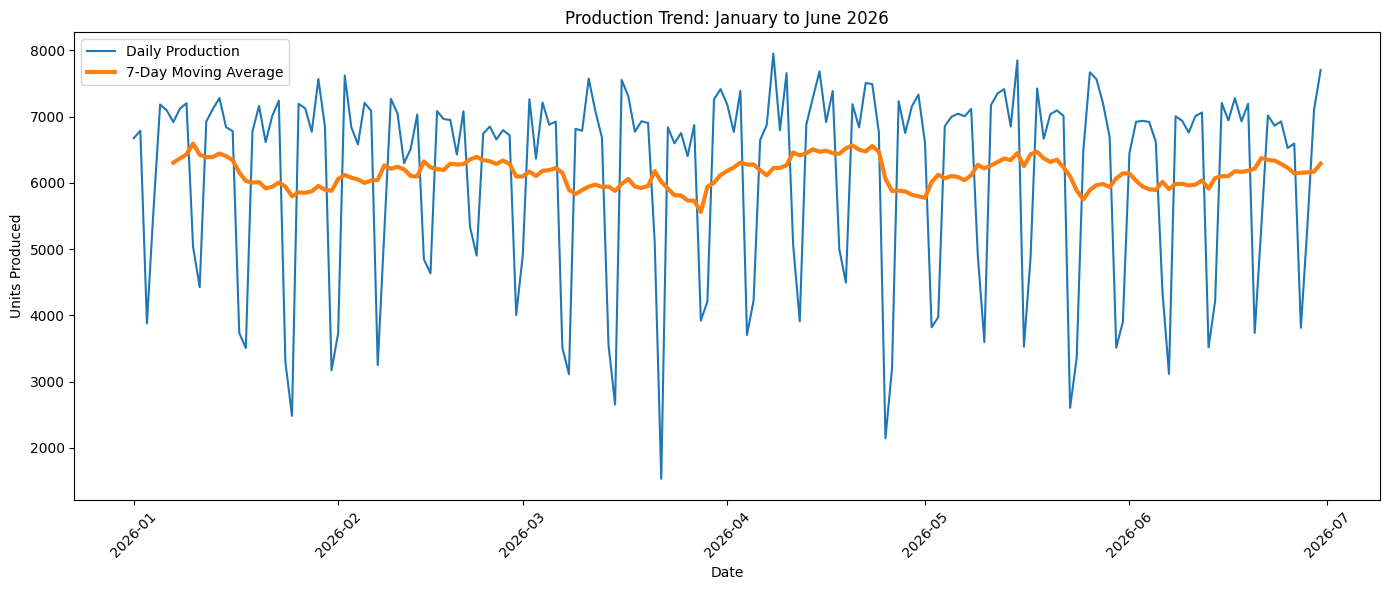

In [27]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_production['Date'],
    daily_production['Units Produced'],
    label='Daily Production'
)

plt.plot(
    daily_production['Date'],
    daily_production['7_Day_Average'],
    label='7-Day Moving Average',
    linewidth=3
)

plt.title('Production Trend: January to June 2026')
plt.xlabel('Date')
plt.ylabel('Units Produced')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
monthly_production = (
    df.groupby(df['Date'].dt.to_period('M'))['Units Produced']
    .sum()
    .reset_index()
)

monthly_production['Date'] = monthly_production['Date'].astype(str)

print(monthly_production)

      Date  Units Produced
0  2026-01          189367
1  2026-02          173742
2  2026-03          185731
3  2026-04          189438
4  2026-05          187155
5  2026-06          186379


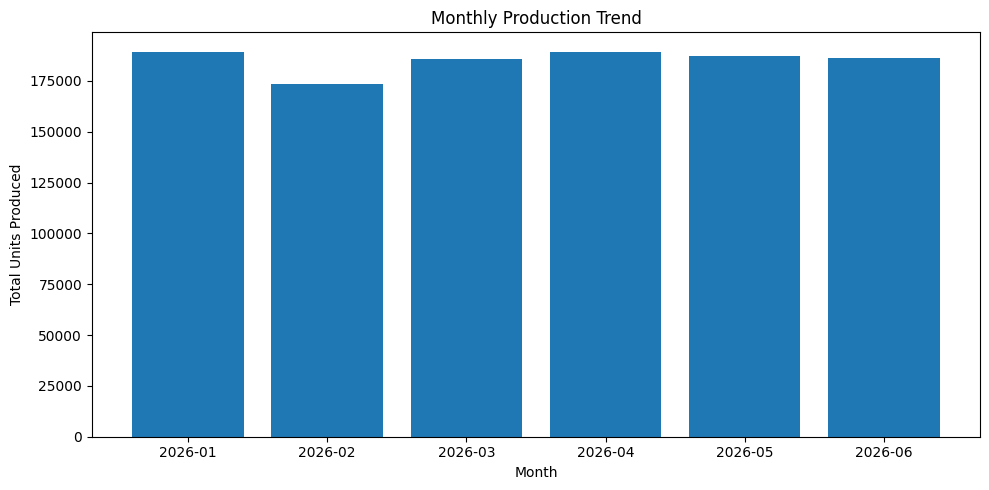

In [29]:
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_production['Date'],
    monthly_production['Units Produced']
)

plt.title('Monthly Production Trend')
plt.xlabel('Month')
plt.ylabel('Total Units Produced')

plt.tight_layout()
plt.show()

In [30]:
print(monthly_production)

      Date  Units Produced
0  2026-01          189367
1  2026-02          173742
2  2026-03          185731
3  2026-04          189438
4  2026-05          187155
5  2026-06          186379


In [31]:
machine_analysis = df.groupby('Machine ID').agg({
    'Units Produced': 'sum',
    'Units Defective': 'sum',
    'Downtime Minutes': 'sum',
    'Good Units': 'sum'
}).reset_index()

machine_analysis = machine_analysis.sort_values(
    'Units Produced',
    ascending=False
)

print(machine_analysis)

  Machine ID  Units Produced  Units Defective  Downtime Minutes  Good Units
0      M-101          225537             6807             10819      218730
4      M-105          223244             7069             10860      216175
1      M-102          222809             7112             11289      215697
2      M-103          221656             6881             11012      214775
3      M-104          218566             6632             10648      211934


In [32]:
machine_analysis['Downtime %'] = (
    machine_analysis['Downtime Minutes'] /
    df['Downtime Minutes'].sum()
) * 100

print(machine_analysis)

  Machine ID  Units Produced  Units Defective  Downtime Minutes  Good Units  \
0      M-101          225537             6807             10819      218730   
4      M-105          223244             7069             10860      216175   
1      M-102          222809             7112             11289      215697   
2      M-103          221656             6881             11012      214775   
3      M-104          218566             6632             10648      211934   

   Downtime %  
0   19.804862  
4   19.879915  
1   20.665227  
2   20.158161  
3   19.491836  


In [33]:
top_downtime_machines = machine_analysis.sort_values(
    'Downtime Minutes',
    ascending=False
)

print(top_downtime_machines)

  Machine ID  Units Produced  Units Defective  Downtime Minutes  Good Units  \
1      M-102          222809             7112             11289      215697   
2      M-103          221656             6881             11012      214775   
4      M-105          223244             7069             10860      216175   
0      M-101          225537             6807             10819      218730   
3      M-104          218566             6632             10648      211934   

   Downtime %  
1   20.665227  
2   20.158161  
4   19.879915  
0   19.804862  
3   19.491836  


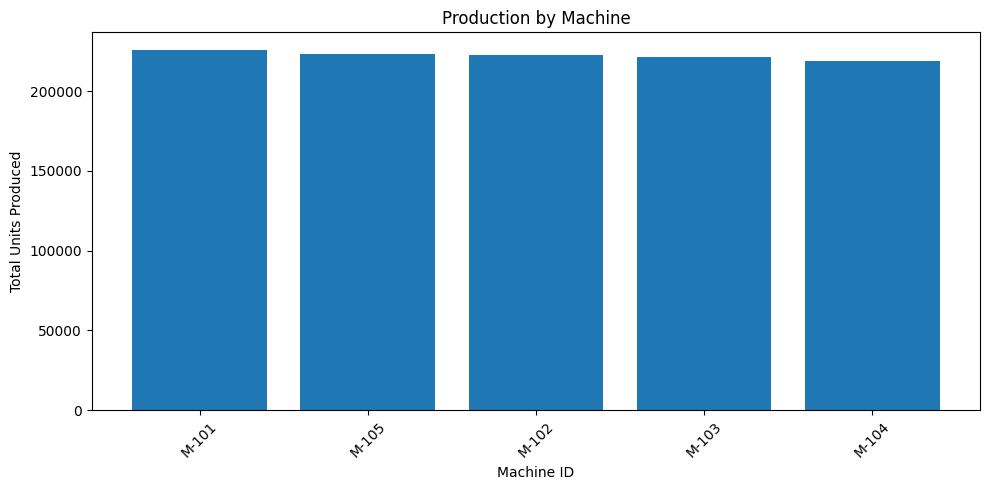

In [34]:
plt.figure(figsize=(10, 5))

plt.bar(
    machine_analysis['Machine ID'],
    machine_analysis['Units Produced']
)

plt.title('Production by Machine')
plt.xlabel('Machine ID')
plt.ylabel('Total Units Produced')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:
print(machine_analysis)

  Machine ID  Units Produced  Units Defective  Downtime Minutes  Good Units  \
0      M-101          225537             6807             10819      218730   
4      M-105          223244             7069             10860      216175   
1      M-102          222809             7112             11289      215697   
2      M-103          221656             6881             11012      214775   
3      M-104          218566             6632             10648      211934   

   Downtime %  
0   19.804862  
4   19.879915  
1   20.665227  
2   20.158161  
3   19.491836  


In [36]:
downtime_reason = (
    df.groupby('Downtime Reason')['Downtime Minutes']
    .sum()
    .sort_values(ascending=False)
)

print(downtime_reason)

Downtime Reason
Material Shortage    10102
Machine Breakdown     9972
Maintenance           9353
Changeover            9018
Quality Check         8598
Power Outage          7585
No Breakdown             0
Name: Downtime Minutes, dtype: int64


In [37]:
downtime_reason_pct = (
    downtime_reason / downtime_reason.sum()
) * 100

print(downtime_reason_pct)

Downtime Reason
Material Shortage    18.492348
Machine Breakdown    18.254375
Maintenance          17.121256
Changeover           16.508018
Quality Check        15.739181
Power Outage         13.884821
No Breakdown          0.000000
Name: Downtime Minutes, dtype: float64


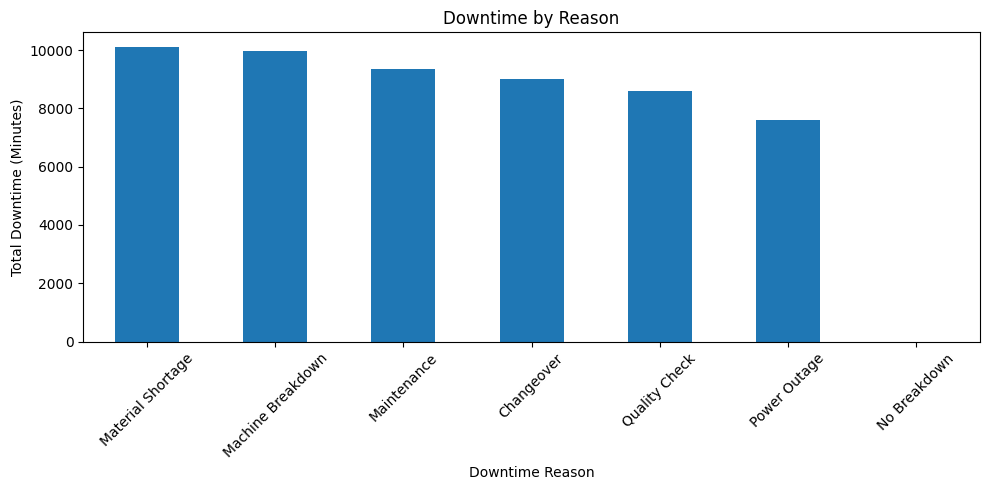

In [38]:
plt.figure(figsize=(10, 5))

downtime_reason.plot(kind='bar')

plt.title('Downtime by Reason')
plt.xlabel('Downtime Reason')
plt.ylabel('Total Downtime (Minutes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [40]:
shift_production = df.groupby('Shift').agg({
    'Units Produced': 'sum',
    'Downtime Minutes': 'sum',
    'Units Defective': 'sum'
}).sort_values('Units Produced', ascending=False)

print(shift_production)

         Units Produced  Downtime Minutes  Units Defective
Shift                                                     
Evening          374904             18880            11745
Morning          368611             17076            11387
Night            368297             18672            11369


In [42]:
shift_avg = df.groupby('Shift').agg({
    'Units Produced': 'mean',
    'Downtime Minutes': 'mean',
    'Units Defective': 'mean'
})

print(shift_avg)

         Units Produced  Downtime Minutes  Units Defective
Shift                                                     
Evening      465.719255         23.453416        14.590062
Morning      470.167092         21.780612        14.524235
Night        465.609355         23.605563        14.372946


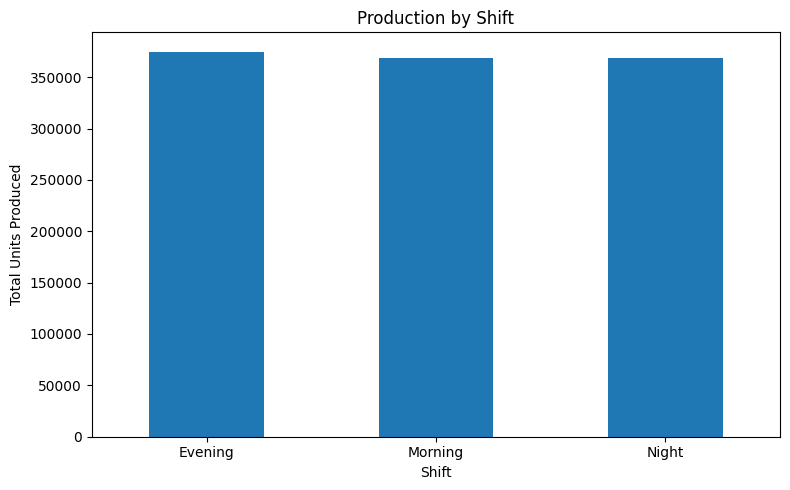

In [43]:
plt.figure(figsize=(8,5))

shift_production['Units Produced'].plot(kind='bar')

plt.title('Production by Shift')
plt.xlabel('Shift')
plt.ylabel('Total Units Produced')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [44]:
machine_downtime_reason = pd.pivot_table(
    df,
    values='Downtime Minutes',
    index='Machine ID',
    columns='Downtime Reason',
    aggfunc='sum',
    fill_value=0
)

print(machine_downtime_reason)

Downtime Reason  Changeover  Machine Breakdown  Maintenance  \
Machine ID                                                    
M-101                  1920               2067         2421   
M-102                  2119               2609         1862   
M-103                  1498               2332         2210   
M-104                  1944               1329         1502   
M-105                  1537               1635         1358   

Downtime Reason  Material Shortage  No Breakdown  Power Outage  Quality Check  
Machine ID                                                                     
M-101                         1786             0          1162           1463  
M-102                         1908             0          1245           1546  
M-103                         1801             0          1486           1685  
M-104                         2254             0          1791           1828  
M-105                         2353             0          1901           2076 

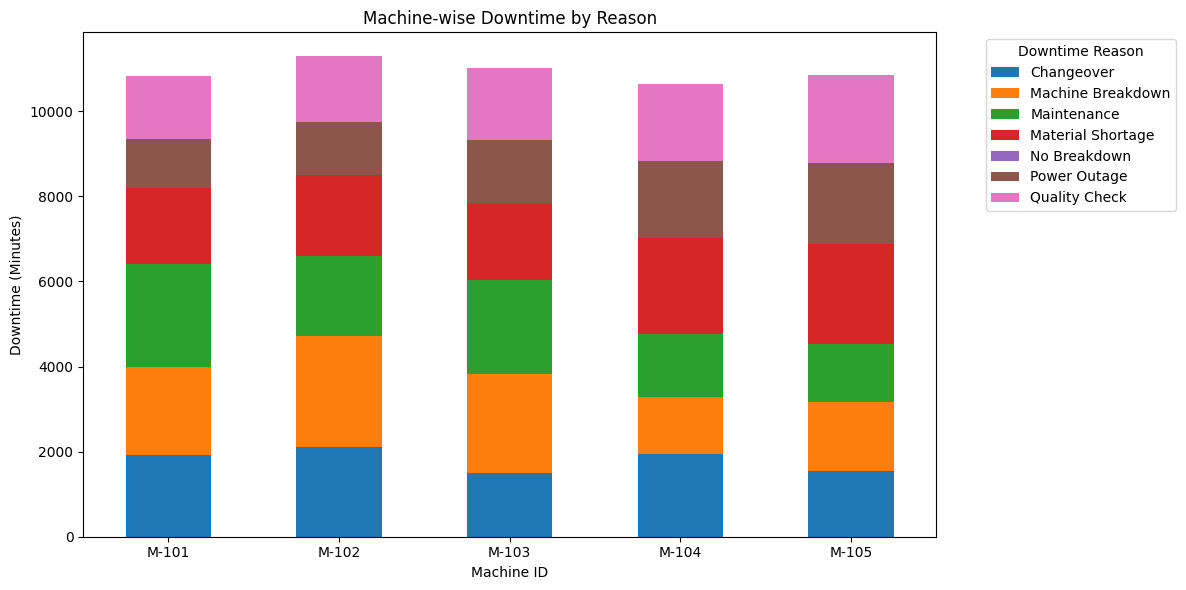

In [45]:
machine_downtime_reason.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6)
)

plt.title('Machine-wise Downtime by Reason')
plt.xlabel('Machine ID')
plt.ylabel('Downtime (Minutes)')
plt.xticks(rotation=0)
plt.legend(title='Downtime Reason', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [46]:
machine_reason = (
    df.groupby(['Machine ID', 'Downtime Reason'])['Downtime Minutes']
    .sum()
    .sort_values(ascending=False)
)

print(machine_reason.head(10))

Machine ID  Downtime Reason  
M-102       Machine Breakdown    2609
M-101       Maintenance          2421
M-105       Material Shortage    2353
M-103       Machine Breakdown    2332
M-104       Material Shortage    2254
M-103       Maintenance          2210
M-102       Changeover           2119
M-105       Quality Check        2076
M-101       Machine Breakdown    2067
M-104       Changeover           1944
Name: Downtime Minutes, dtype: int64


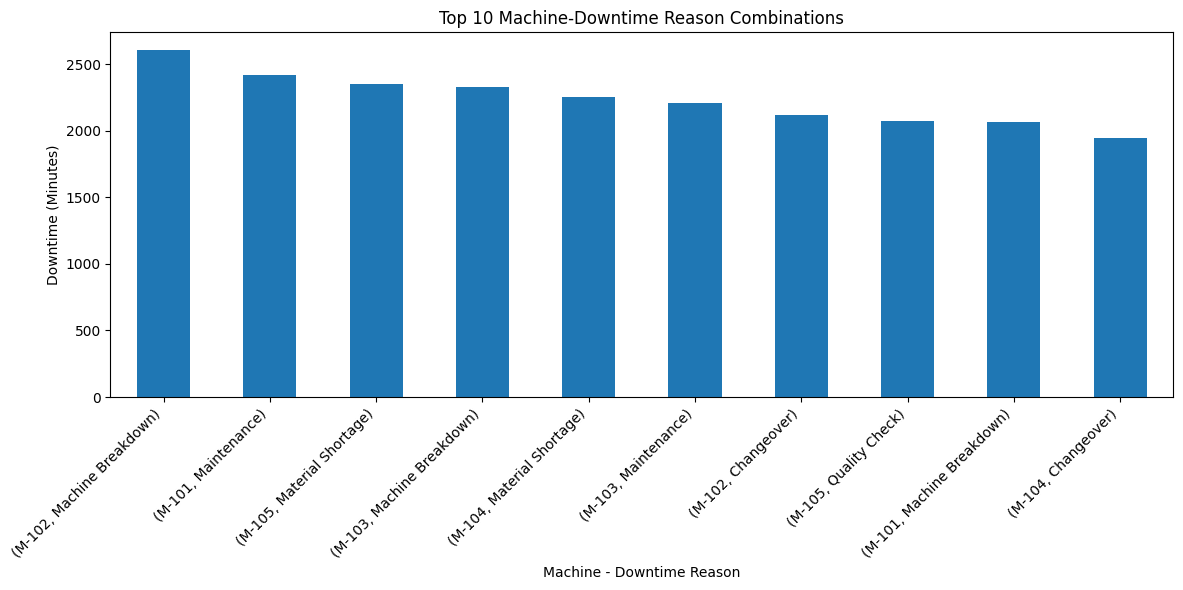

In [47]:
top_machine_reason = (
    df.groupby(['Machine ID', 'Downtime Reason'])['Downtime Minutes']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_machine_reason.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Top 10 Machine-Downtime Reason Combinations')
plt.xlabel('Machine - Downtime Reason')
plt.ylabel('Downtime (Minutes)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [48]:
maintenance_rows = df[
    df['Downtime Reason'].str.contains('maintenance', case=False, na=False)
]

maintenance_downtime = maintenance_rows['Downtime Minutes'].sum()

print("Total Maintenance Downtime:", maintenance_downtime, "minutes")

Total Maintenance Downtime: 9353 minutes


In [49]:
maintenance_by_machine = (
    maintenance_rows.groupby('Machine ID')['Downtime Minutes']
    .sum()
    .sort_values(ascending=False)
)

print(maintenance_by_machine)

Machine ID
M-101    2421
M-103    2210
M-102    1862
M-104    1502
M-105    1358
Name: Downtime Minutes, dtype: int64


In [50]:
maintenance_share = (
    maintenance_downtime / df['Downtime Minutes'].sum()
) * 100

print("Maintenance Downtime Share:", maintenance_share, "%")

Maintenance Downtime Share: 17.121256498498937 %


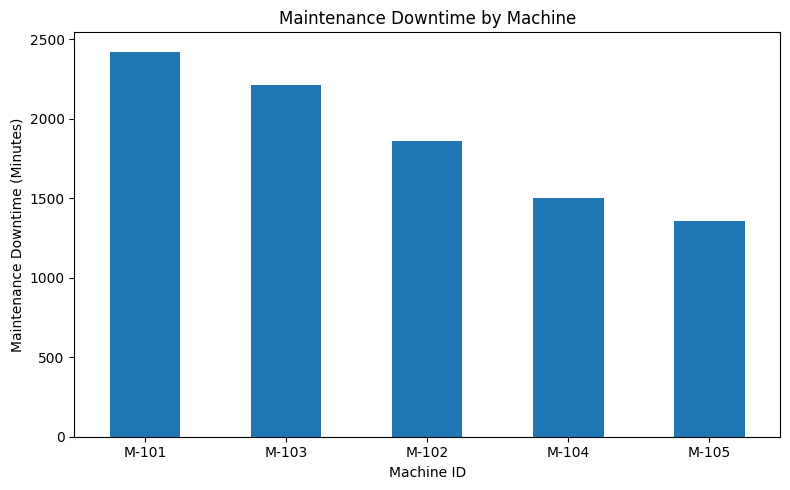

In [51]:
plt.figure(figsize=(8,5))

maintenance_by_machine.plot(kind='bar')

plt.title('Maintenance Downtime by Machine')
plt.xlabel('Machine ID')
plt.ylabel('Maintenance Downtime (Minutes)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [52]:
# Availability
df['Availability'] = df['Run Time'] / df['Planned Time']

# Performance
df['Performance'] = (
    df['Ideal Cycle Time'] * df['Units Produced']
) / df['Run Time']

# Quality
df['Quality'] = df['Good Units'] / df['Units Produced']

# OEE
df['OEE'] = (
    df['Availability']
    * df['Performance']
    * df['Quality']
)

df['OEE_Percentage'] = df['OEE'] * 100

print("Average Availability:",
      df['Availability'].mean() * 100, "%")

print("Average Performance:",
      df['Performance'].mean() * 100, "%")

print("Average Quality:",
      df['Quality'].mean() * 100, "%")

print("Average OEE:",
      df['OEE_Percentage'].mean(), "%")

Average Availability: 95.21813725490196 %
Average Performance: 100.0 %
Average Quality: 96.87109719594179 %
Average OEE: 92.25959647085993 %


In [53]:
print(df[['Availability',
          'Performance',
          'Quality',
          'OEE_Percentage']].describe())

       Availability   Performance      Quality  OEE_Percentage
count   2380.000000  2.380000e+03  2380.000000     2380.000000
mean       0.952181  1.000000e+00     0.968711       92.259596
std        0.075979  1.034614e-16     0.014288        7.710253
min        0.750000  1.000000e+00     0.904535       69.846491
25%        0.912500  1.000000e+00     0.959184       87.963467
50%        1.000000  1.000000e+00     0.969176       96.052632
75%        1.000000  1.000000e+00     0.980227       97.512438
max        1.000000  1.000000e+00     0.992405       99.200000


In [54]:
machine_oee = (
    df.groupby('Machine ID')['OEE_Percentage']
    .mean()
    .sort_values(ascending=False)
)

print(machine_oee)

Machine ID
M-101    92.442298
M-104    92.418000
M-105    92.199396
M-103    92.179519
M-102    92.057305
Name: OEE_Percentage, dtype: float64


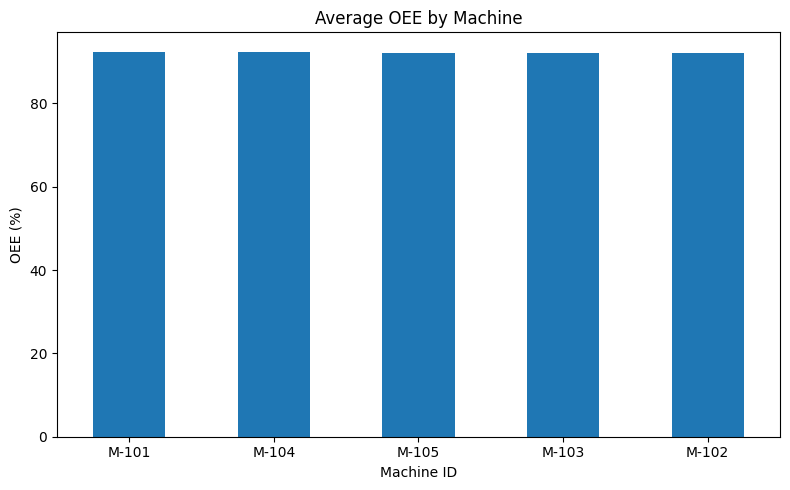

In [55]:
plt.figure(figsize=(8,5))

machine_oee.plot(kind='bar')

plt.title('Average OEE by Machine')
plt.xlabel('Machine ID')
plt.ylabel('OEE (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [56]:
ml_df = df[
    [
        'Units Produced',
        'Downtime Minutes',
        'Planned Time',
        'Run Time',
        'Ideal Cycle Time',
        'Shift',
        'Machine ID',
        'Product',
        'Operator'
    ]
].copy()

print(ml_df.head())
print(ml_df.shape)

   Units Produced  Downtime Minutes  Planned Time  Run Time  Ideal Cycle Time  \
0             407                 0           480       480          1.179361   
1             401                37           480       443          1.104738   
2             464                 0           480       480          1.034483   
3             538                37           480       443          0.823420   
4             540                 0           480       480          0.888889   

     Shift Machine ID        Product   Operator  
0  Morning      M-101  Steel Bracket  A. Ramesh  
1  Morning      M-102  Steel Bracket    M. Nair  
2  Morning      M-103    Motor Shaft   R. Singh  
3  Morning      M-104   Gear Housing    M. Nair  
4  Morning      M-105  Steel Bracket   K. Reddy  
(2380, 9)


In [57]:
ml_df = pd.get_dummies(
    ml_df,
    columns=['Shift', 'Machine ID', 'Product', 'Operator'],
    drop_first=True
)

print(ml_df.shape)

(2380, 21)


In [58]:
X = ml_df.drop(columns=['Units Produced'])
y = ml_df['Units Produced']

print("X shape:", X.shape)
print("Y shape:", y.shape)

X shape: (2380, 20)
Y shape: (2380,)


In [59]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1904, 20)
Testing data: (476, 20)


In [60]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [61]:
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.head().values)

print("\nPredicted values:")
print(y_pred[:5])

Actual values:
[500 624 392 485 369]

Predicted values:
[498.81 624.   391.88 484.54 371.17]


In [62]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²   :", r2)

MAE : 0.9810924369747848
RMSE: 2.2299266106927442
R²   : 0.9991581074639688


In [63]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    'Importance',
    ascending=False
)

print(feature_importance.head(15))

                   Feature  Importance
3         Ideal Cycle Time    0.769006
0         Downtime Minutes    0.115408
2                 Run Time    0.114908
5              Shift_Night    0.000056
11   Product_Steel Bracket    0.000055
7         Machine ID_M-103    0.000052
6         Machine ID_M-102    0.000051
18       Operator_S. Kumar    0.000047
10     Product_Motor Shaft    0.000045
8         Machine ID_M-104    0.000044
4            Shift_Morning    0.000044
15        Operator_N. Iyer    0.000044
9         Machine ID_M-105    0.000043
12  Product_Valve Assembly    0.000038
16        Operator_P. Devi    0.000037


<Figure size 1000x600 with 0 Axes>

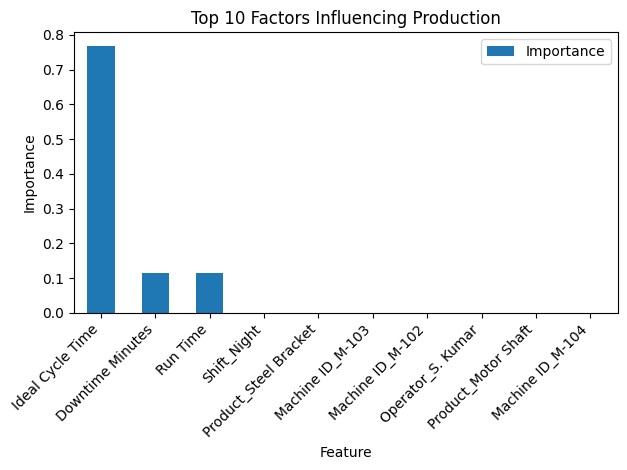

In [64]:
plt.figure(figsize=(10,6))

feature_importance.head(10).plot(
    x='Feature',
    y='Importance',
    kind='bar'
)

plt.title('Top 10 Factors Influencing Production')
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [65]:
daily_production = (
    df.groupby('Date')['Units Produced']
    .sum()
    .reset_index()
)

daily_production['7_Day_Average'] = (
    daily_production['Units Produced']
    .rolling(window=7)
    .mean()
)

print(daily_production.tail(15))

          Date  Units Produced  7_Day_Average
166 2026-06-16            6943    6102.285714
167 2026-06-17            7279    6176.571429
168 2026-06-18            6929    6165.285714
169 2026-06-19            7194    6184.142857
170 2026-06-20            3736    6215.285714
171 2026-06-21            5336    6374.714286
172 2026-06-22            7017    6347.714286
173 2026-06-23            6864    6336.428571
174 2026-06-24            6927    6286.142857
175 2026-06-25            6526    6228.571429
176 2026-06-26            6594    6142.857143
177 2026-06-27            3814    6154.000000
178 2026-06-28            5363    6157.857143
179 2026-06-29            7106    6170.571429
180 2026-06-30            7704    6290.571429


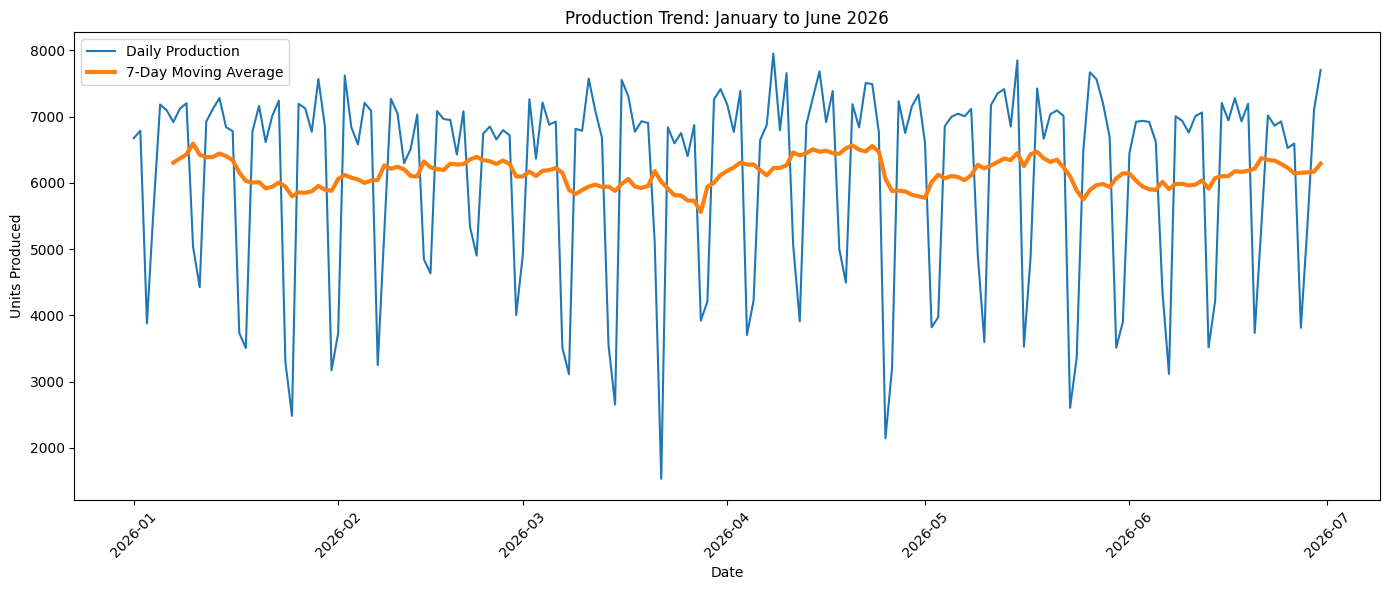

In [66]:
plt.figure(figsize=(14,6))

plt.plot(
    daily_production['Date'],
    daily_production['Units Produced'],
    label='Daily Production'
)

plt.plot(
    daily_production['Date'],
    daily_production['7_Day_Average'],
    label='7-Day Moving Average',
    linewidth=3
)

plt.title('Production Trend: January to June 2026')
plt.xlabel('Date')
plt.ylabel('Units Produced')
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [69]:
machine_summary = df.groupby('Machine ID').agg({
    'Units Produced': 'sum',
    'Units Defective': 'sum',
    'Downtime Minutes': 'sum',
    'Good Units': 'sum'
}).sort_values('Units Produced')

print(machine_summary)

            Units Produced  Units Defective  Downtime Minutes  Good Units
Machine ID                                                               
M-104               218566             6632             10648      211934
M-103               221656             6881             11012      214775
M-102               222809             7112             11289      215697
M-105               223244             7069             10860      216175
M-101               225537             6807             10819      218730


In [70]:
shift_summary = df.groupby('Shift').agg({
    'Units Produced': ['sum', 'mean'],
    'Downtime Minutes': ['sum', 'mean'],
    'Units Defective': ['sum', 'mean']
})

print(shift_summary)

        Units Produced             Downtime Minutes             \
                   sum        mean              sum       mean   
Shift                                                            
Evening         374904  465.719255            18880  23.453416   
Morning         368611  470.167092            17076  21.780612   
Night           368297  465.609355            18672  23.605563   

        Units Defective             
                    sum       mean  
Shift                               
Evening           11745  14.590062  
Morning           11387  14.524235  
Night             11369  14.372946  
